In [138]:
import h5py
import numpy as np

def read_mat73_obj(f, obj):

    # dataset
    if isinstance(obj, h5py.Dataset):

        data = obj[()]

        # MATLAB cell：里面存的是 reference
        if data.dtype == h5py.ref_dtype or data.dtype.kind == "O":

            result = []

            for ref in data.flatten():

                if not ref:
                    result.append(None)
                    continue

                sub_obj = f[ref]

                result.append(
                    read_mat73_obj(f, sub_obj)
                )

            return result

        # MATLAB complex
        if data.dtype.names is not None:
            if "real" in data.dtype.names and "imag" in data.dtype.names:
                return data["real"] + 1j * data["imag"]

        return np.array(data)

    # group
    elif isinstance(obj, h5py.Group):

        return {
            key: read_mat73_obj(f, obj[key])
            for key in obj.keys()
        }

In [139]:
filename = "single_parameter_u_scan_small_002.mat"

with h5py.File(filename, "r") as f:

    data = read_mat73_obj(f, f["u_all"])


filename = "single_parameter_u_scan_small_03.mat"

with h5py.File(filename, "r") as f:

    data1 = read_mat73_obj(f, f["u_all"])


filename = "single_parameter_u_scan_small_075.mat"

with h5py.File(filename, "r") as f:

    data2 = read_mat73_obj(f, f["u_all"])

In [140]:
data[0][5]

array([[0.01526404],
       [0.02196576],
       [0.02196576],
       ...,
       [0.0283627 ],
       [0.01839692],
       [0.01441728]])

In [141]:
y = []
y1 = []
y2 = []
for i in range(len(data)):
    y.append(np.mean(data[i][5]))
    y1.append(np.mean(data1[i][5]))
    y2.append(np.mean(data2[i][5]))

In [142]:
filename = "single_parameter_u_scan_002.mat"

with h5py.File(filename, "r") as f:

    data = read_mat73_obj(f, f["u_all"])


filename = "single_parameter_u_scan_03.mat"

with h5py.File(filename, "r") as f:

    data1 = read_mat73_obj(f, f["u_all"])


filename = "single_parameter_u_scan_075.mat"

with h5py.File(filename, "r") as f:

    data2 = read_mat73_obj(f, f["u_all"])

In [143]:
z = []
z1 = []
z2 = []
for i in range(len(data)):
    z.append(np.real(np.mean(data[i][5])))
    z1.append(np.real(np.mean(data1[i][5])))
    z2.append(np.real(np.mean(data2[i][5])))

In [144]:
filename = "single_parameter_u_scan_small_002.mat"

with h5py.File(filename, "r") as f:
    print(list(f.keys()))

['#refs#', 'h_values', 'u_all']


In [145]:
with h5py.File(filename, "r") as f:
    f_values = np.array(f["h_values"])
    u_all = np.array(f["u_all"]).squeeze()

print(f_values.shape)
print(u_all.shape)

(151, 1)
(151,)


/home/qinjiajie/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/qinjiajie/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


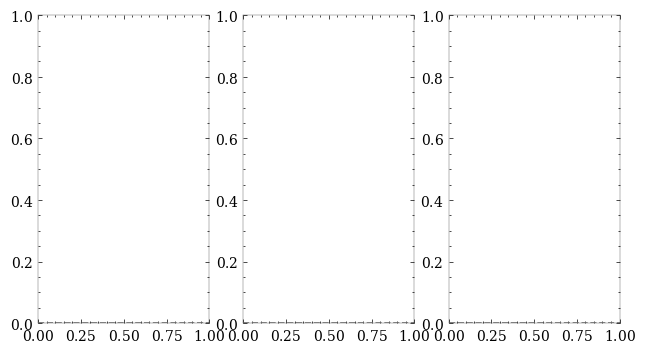

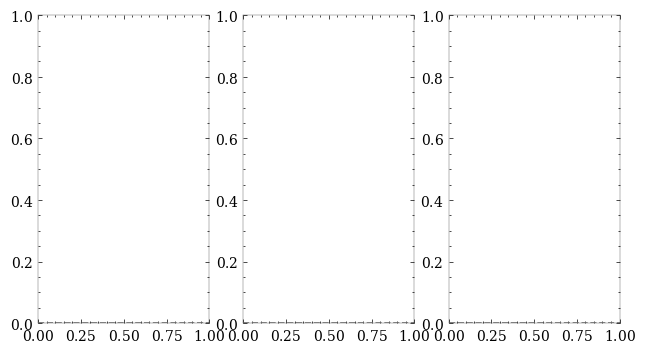

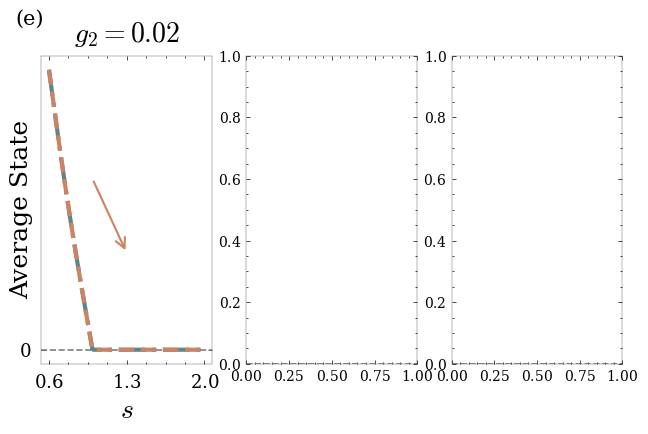

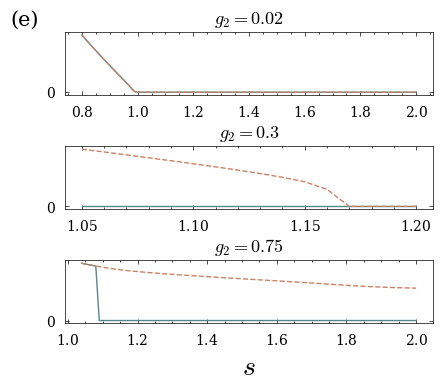

In [146]:
import matplotlib.pyplot as plt
import scienceplots

from matplotlib.ticker import MaxNLocator, FuncFormatter
with plt.style.context(['science', 'no-latex']): 
    fig, ax = plt.subplots(
        3, 1,
        figsize=(4.5, 4),
        sharex=False
    )
    
    # 第一组
    ax[0].plot(f_values[30:], y[30:], '-', label='Lower Initial State', color = '#58878A')
    ax[0].plot(f_values[30:], z[30:], '--', label='Higher Initial State', color = '#CC8264')
    # ax[0].legend(frameon=False,fontsize=10, loc='upper right')
    ax[0].tick_params(axis='both', labelsize=10, pad=7)
    ax[0].set_title(r'$g_2 = 0.02$',fontsize=13)
    # ax[0].set_xlim([0.75,1.5])
    # ax[0].set_ylim([-0.005,0.03])
    ax[0].text(-0.15,1.1,'(e)',fontsize=15,transform=ax[0].transAxes)
    ax[0].set_yticks([0])
    
    
    # 第二组
    ax[1].plot(f_values[55:71], y1[55:71], '-', label='Lower Initial State', color = '#58878A')
    ax[1].plot(f_values[55:71], z1[55:71], '--', label='Higher Initial State', color = '#CC8264')
    # ax[1].legend(frameon=False,fontsize=9, loc='upper right')
    ax[1].tick_params(axis='both', labelsize=10, pad=7)
    ax[1].set_title(r'$g_2 = 0.3$',fontsize=13)
    ax[1].set_yticks([0])
    ax[1].set_xticks([1.05,  1.1, 1.15, 1.2])
    # ax[1].set_xlim([0.75,1.5])
    # ax[1].set_ylim([-0.005,0.05])
    
    # 第三组
    ax[2].plot(f_values[54:], y2[54:], '-', label='Lower Initial State', color = '#58878A')
    ax[2].plot(f_values[54:], z2[54:], '--', label='Higher Initial State', color = '#CC8264')
    # ax[2].legend(frameon=False,fontsize=9, loc='upper right')
    ax[2].tick_params(axis='both', labelsize=10, pad=7)
    ax[2].set_title(r'$g_2 = 0.75$',fontsize=13)
    ax[2].set_yticks([0])
    # ax[2].set_xlim([0.75,1.5])
    # ax[2].set_ylim([-0.005,0.06])
    
    ax[2].set_xlabel(r'$s$',fontsize=20)
    # ax[2].set_ylabel('Average\n State',fontsize=14)

    # fig.supylabel(' ',fontsize=18,x=0.11)
    plt.tight_layout(h_pad=0.3)
    fig.supylabel('',fontsize=18,x=0.05)
# plt.savefig("GRN_hysteresis.pdf", format='pdf', dpi=300)
plt.show()

/home/qinjiajie/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/qinjiajie/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


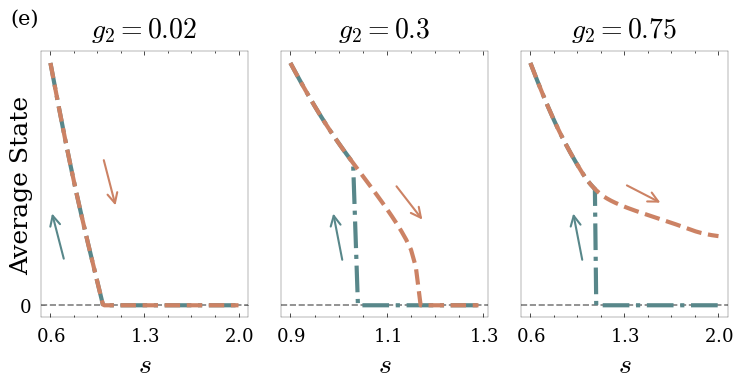

In [189]:
import matplotlib.pyplot as plt
import scienceplots
from matplotlib.patches import FancyArrowPatch

from matplotlib.ticker import MaxNLocator, FuncFormatter
with plt.style.context(['science', 'no-latex']): 
    fig, ax = plt.subplots(
        1, 3,
        figsize=(7.5, 4),
        sharex=False
    )
    bwith = 0.2

    for a in ax:
        a.spines['bottom'].set_linewidth(bwith)
        a.spines['left'].set_linewidth(bwith)
        a.spines['top'].set_linewidth(bwith)
        a.spines['right'].set_linewidth(bwith)
        a.axhline(0, color='0.5', linestyle='--', linewidth=1.2)
    
    # 第一组
    ax[0].plot(f_values[10:], y[10:], '-.',linewidth=3, label='Lower Initial State', color = '#58878A')
    ax[0].plot(f_values[10:], z[10:], '--',linewidth=3, label='Higher Initial State', color = '#CC8264')
    # ax[0].legend(frameon=False,fontsize=10, loc='upper right')
    ax[0].tick_params(axis='both', labelsize=13, pad=7)
    ax[0].set_title(r'$g_2 = 0.02$',fontsize=20, pad=10)
    # ax[0].set_xlim([0.75,1.5])
    # ax[0].set_ylim([-0.005,0.03])
    ax[0].text(-0.15,1.1,'(e)',fontsize=15,transform=ax[0].transAxes)
    ax[0].set_yticks([0])
    ax[0].set_xlabel(r'$s$',fontsize=20)
    ax[0].set_ylabel('Average State',fontsize=18,labelpad=-10)
    xmin, xmax = ax[0].get_xlim()
    ax[0].set_xticks(np.linspace(xmin, xmax, 3))
    ax[0].set_xticks([0.6,  1.3, 2])
    
    k = -3             # 斜率
    L = 0.2
    dx = L / np.sqrt(1 + k**2)
    dy = k * dx
    xx, yy = 0.3, 0.6   # 起点
    arrow = FancyArrowPatch(
        (xx, yy), (xx + dx, yy + dy),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#CC8264',
        transform=ax[0].transAxes
    )
    ax[0].add_patch(arrow)

    xx, yy = 0.05, 0.4   # 起点
    arrow = FancyArrowPatch(
        (xx+dx, yy+dy), (xx , yy ),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#58878A',
        transform=ax[0].transAxes
    )
    ax[0].add_patch(arrow)
    
    
    # 第二组
    ax[1].plot(f_values[40:80], y1[40:80], '-.',linewidth=3, label='Lower Initial State', color = '#58878A')
    ax[1].plot(f_values[40:80], z1[40:80], '--',linewidth=3, label='Higher Initial State', color = '#CC8264')
    # ax[1].legend(frameon=False,fontsize=9, loc='upper right')
    ax[1].tick_params(axis='both', labelsize=13, pad=7)
    ax[1].set_title(r'$g_2 = 0.3$',fontsize=20, pad=10)
    # ax[1].set_yticks([0])
    ax[1].set_yticks([])
    # xmin, xmax = ax[1].get_xlim()
    # ax[1].set_xticks(np.linspace(xmin, xmax, 3))
    # ax[1].set_xticks([1.05,  1.1, 1.15, 1.2])
    ax[1].set_xlabel(r'$s$',fontsize=20)
    ax[1].set_xticks([0.9, 1.1, 1.3])
    # ax[1].set_xlim([0.75,1.5])
    # ax[1].set_ylim([-0.005,0.05])

    k = -1             # 斜率
    L = 0.2
    dx = L / np.sqrt(1 + k**2)
    dy = k * dx
    
    xx, yy = 0.55, 0.5   # 起点
    arrow = FancyArrowPatch(
        (xx, yy), (xx + dx, yy + dy),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#CC8264',
        transform=ax[1].transAxes
    )
    ax[1].add_patch(arrow)
    k = -4             # 斜率
    L = 0.2
    dx = L / np.sqrt(1 + k**2)
    dy = k * dx
    xx, yy = 0.25, 0.4   # 起点
    arrow = FancyArrowPatch(
        (xx+dx, yy+dy), (xx , yy ),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#58878A',
        transform=ax[1].transAxes
    )
    ax[1].add_patch(arrow)
    
    
    # 第三组
    ax[2].plot(f_values[10:], y2[10:], '-.',linewidth=3, label='Lower Initial State', color = '#58878A')
    ax[2].plot(f_values[10:], z2[10:], '--',linewidth=3, label='Higher Initial State', color = '#CC8264')
    # ax[2].legend(frameon=False,fontsize=9, loc='upper right')
    ax[2].tick_params(axis='both', labelsize=13, pad=7)
    ax[2].set_title(r'$g_2 = 0.75$',fontsize=20, pad=10)
    # ax[2].set_yticks([0])
    ax[2].set_yticks([])
    # ax[2].set_xlim([0.75,1.5])
    # ax[2].set_ylim([-0.005,0.06])
    ax[2].set_xticks([0.6,  1.3, 2])
    
    ax[2].set_xlabel(r'$s$',fontsize=20)
    # ax[2].set_ylabel('Average\n State',fontsize=14)
    k = -0.4             # 斜率
    L = 0.2
    dx = L / np.sqrt(1 + k**2)
    dy = k * dx
    xx, yy = 0.5, 0.5   # 起点
    arrow = FancyArrowPatch(
        (xx, yy), (xx + dx, yy + dy),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#CC8264',
        transform=ax[2].transAxes
    )
    ax[2].add_patch(arrow)
    
    k = -4             # 斜率
    L = 0.2
    dx = L / np.sqrt(1 + k**2)
    dy = k * dx
    xx, yy = 0.25, 0.4   # 起点
    arrow = FancyArrowPatch(
        (xx+dx, yy+dy), (xx , yy ),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#58878A',
        transform=ax[2].transAxes
    )
    ax[2].add_patch(arrow)
    

    # fig.supylabel(' ',fontsize=18,x=0.11)
    
    plt.tight_layout()
    fig.subplots_adjust(wspace=0.16)
plt.savefig("GRN_hysteresis.pdf", format='pdf', dpi=300)
plt.show()